# RAGTruth Split-Strategy Experiment

TF-IDF + Logistic Regression experiment for comparing response-level and source-task-level validation splits. The model uses response text only. The official test set is reserved for the final evaluation.

In [2]:
import subprocess
import sys

try:
    import torch
except ImportError:
    print('PyTorch is not installed in this runtime.')
    torch = None

if torch is not None:
    print('Python:', sys.version.split()[0])
    print('PyTorch:', torch.__version__)
    print('CUDA available:', torch.cuda.is_available())
    if torch.cuda.is_available():
        print('CUDA version:', torch.version.cuda)
        print('GPU:', torch.cuda.get_device_name(0))
        print('GPU memory:', f'{torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} GB')
    else:
        print('No GPU detected. Select a GPU runtime before running the encoder section.')

try:
    result = subprocess.run(
        ['nvidia-smi', '--query-gpu=name,memory.total,driver_version', '--format=csv,noheader'],
        capture_output=True, text=True, check=False,
    )
    if result.returncode == 0:
        print('nvidia-smi:', result.stdout.strip())
    else:
        print('nvidia-smi is unavailable in this runtime.')
except FileNotFoundError:
    print('nvidia-smi is unavailable in this runtime.')

Python: 3.13.16
PyTorch: 2.14.1+cu130
CUDA available: True
CUDA version: 13.0
GPU: NVIDIA L4
GPU memory: 22.0 GB
nvidia-smi: NVIDIA L4, 23034 MiB, 580.82.07


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
from pathlib import Path

DATASET_DIR = Path("/content/drive/MyDrive/RAGTruth/dataset")

print(DATASET_DIR)
print("response.jsonl exists:", (DATASET_DIR / "response.jsonl").exists())
print("source_info.jsonl exists:", (DATASET_DIR / "source_info.jsonl").exists())

/content/drive/MyDrive/RAGTruth/dataset
response.jsonl exists: True
source_info.jsonl exists: True


In [5]:
from pathlib import Path
import json
import importlib.metadata as importlib_metadata
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'research').exists() and (PROJECT_ROOT.parent / 'research').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
LOCAL_DATASET_DIR = PROJECT_ROOT / 'RAGTruth' / 'dataset'
COLAB_DATASET_DIR = Path('/content/drive/MyDrive/RAGTruth/dataset')
DATASET_DIR = COLAB_DATASET_DIR if COLAB_DATASET_DIR.exists() else LOCAL_DATASET_DIR

# Drive storage survives Colab runtime resets; local storage is a fallback.
DRIVE_RESULTS_DIR = Path('/content/drive/MyDrive/RAGTruth-experiment-results')
RESULTS_DIR = DRIVE_RESULTS_DIR if DRIVE_RESULTS_DIR.parent.exists() else PROJECT_ROOT / 'results'
TABLES_DIR = RESULTS_DIR / 'tables'
FIGURES_DIR = RESULTS_DIR / 'figures'
TABLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

SEEDS = [13, 42, 2024, 8675309, 12345]
VALIDATION_SIZE = 0.20
print('Dataset directory:', DATASET_DIR)
print('Dataset exists:', (DATASET_DIR / 'response.jsonl').exists())
print('Results directory:', RESULTS_DIR)

Dataset directory: /content/drive/MyDrive/RAGTruth/dataset
Dataset exists: True
Results directory: /content/drive/MyDrive/RAGTruth-experiment-results


If the automatic path is wrong, set `DATASET_DIR` above to the directory containing `response.jsonl` and `source_info.jsonl`. In Colab, mount Drive with **Colab: Mount Google Drive to Server...** before running the configuration cell.

In [6]:
def read_jsonl(path):
    with Path(path).open('r', encoding='utf-8') as file:
        return [json.loads(line) for line in file if line.strip()]

responses = pd.DataFrame(read_jsonl(DATASET_DIR / 'response.jsonl'))
sources = pd.DataFrame(read_jsonl(DATASET_DIR / 'source_info.jsonl'))

def serialize_context(source_row):
    source_info = source_row.get('source_info')
    if source_row['task_type'] == 'QA' and isinstance(source_info, dict):
        return f"Question: {source_info.get('question', '')}\n\nPassages:\n{source_info.get('passages', '')}"
    if isinstance(source_info, (dict, list)):
        return json.dumps(source_info, ensure_ascii=False, sort_keys=True)
    return '' if source_info is None else str(source_info)

sources['context'] = sources.apply(serialize_context, axis=1)
data = responses.merge(sources[['source_id', 'task_type', 'context']], on='source_id', validate='many_to_one')
data['has_hallucination'] = data['labels'].map(lambda x: int(isinstance(x, list) and len(x) > 0))
data = data.rename(columns={'id': 'response_id'})
data['context_plus_response'] = data['context'] + '\n\nResponse: ' + data['response']
data = data[['response_id', 'source_id', 'task_type', 'context', 'response', 'context_plus_response', 'has_hallucination', 'split', 'quality']]
good = data.loc[data['quality'].eq('good')].copy()
train_data = good.loc[good['split'].eq('train')].reset_index(drop=True)
test_data = good.loc[good['split'].eq('test')].reset_index(drop=True)
if set(train_data.source_id) & set(test_data.source_id):
    raise ValueError('Official train/test source-task overlap detected')
print(f'Good training responses: {len(train_data):,}')
print(f'Good official test responses: {len(test_data):,}')
display(train_data.groupby(['task_type', 'has_hallucination']).size().unstack(fill_value=0))
print('Missing contexts:', int(good['context'].isna().sum()))
print('Empty contexts:', int(good['context'].str.strip().eq('').sum()))
display(good.groupby('task_type')['context'].agg(response_count='size', average_characters=lambda values: values.str.len().mean()))

Good training responses: 14,942
Good official test responses: 2,675


has_hallucination,0,1
task_type,,
Data2txt,1623,3672
QA,3346,1546
Summary,3275,1480


Missing contexts: 0
Empty contexts: 0


,response_count,average_characters
task_type,,
Data2txt,6195,2436.522357
QA,5767,1408.909138
Summary,5655,3317.382140


## Split functions and shared evaluation

The response-level split stratifies individual responses by label. The source-task-level split assigns all responses from a source task to one partition and verifies that no source ID crosses the boundary.

In [7]:
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, average_precision_score, f1_score, precision_score, recall_score

def response_split(frame, seed):
    train, valid = train_test_split(frame, test_size=VALIDATION_SIZE, random_state=seed, stratify=frame.has_hallucination)
    return train.reset_index(drop=True), valid.reset_index(drop=True)

def source_task_split(frame, seed):
    splitter = GroupShuffleSplit(n_splits=1, test_size=VALIDATION_SIZE, random_state=seed)
    train_idx, valid_idx = next(splitter.split(frame, groups=frame.source_id))
    train, valid = frame.iloc[train_idx].copy(), frame.iloc[valid_idx].copy()
    if set(train.source_id) & set(valid.source_id):
        raise AssertionError('Source-task leakage detected')
    return train.reset_index(drop=True), valid.reset_index(drop=True)

def make_model(seed):
    return Pipeline([
        ('tfidf', TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=100000, sublinear_tf=True)),
        ('classifier', LogisticRegression(max_iter=2000, class_weight='balanced', solver='liblinear', random_state=seed)),
    ])

def metrics(y_true, probabilities):
    predictions = (probabilities >= 0.5).astype(int)
    return {'f1': f1_score(y_true, predictions, zero_division=0),
            'precision': precision_score(y_true, predictions, zero_division=0),
            'recall': recall_score(y_true, predictions, zero_division=0),
            'pr_auc': average_precision_score(y_true, probabilities),
            'accuracy': accuracy_score(y_true, predictions)}

def evaluate_split(train, valid, seed, strategy):
    model = make_model(seed)
    model.fit(train.response, train.has_hallucination)
    probabilities = model.predict_proba(valid.response)[:, 1]
    row = metrics(valid.has_hallucination, probabilities)
    row.update({'strategy': strategy, 'seed': seed, 'train_responses': len(train), 'validation_responses': len(valid),
                'train_source_tasks': train.source_id.nunique(), 'validation_source_tasks': valid.source_id.nunique(),
                'validation_positive_rate': valid.has_hallucination.mean()})
    return row

## Source-task overlap and split-balance diagnostics

These diagnostics directly measure the leakage opportunity in the response-level split and verify that the grouped split prevents it.

In [8]:
diagnostic_rows = []
for seed in SEEDS:
    for strategy, splitter in [('response_level', response_split), ('source_task_level', source_task_split)]:
        train, valid = splitter(train_data, seed)
        overlap = set(train.source_id) & set(valid.source_id)
        diagnostic_rows.append({
            'strategy': strategy,
            'seed': seed,
            'train_responses': len(train),
            'validation_responses': len(valid),
            'train_source_tasks': train.source_id.nunique(),
            'validation_source_tasks': valid.source_id.nunique(),
            'overlapping_source_tasks': len(overlap),
            'validation_positive_rate': valid.has_hallucination.mean(),
        })
split_diagnostics = pd.DataFrame(diagnostic_rows)
display(split_diagnostics)
split_diagnostics.to_csv(TABLES_DIR / 'split_diagnostics_by_seed.csv', index=False)
assert (split_diagnostics.loc[split_diagnostics.strategy == 'source_task_level', 'overlapping_source_tasks'] == 0).all()
assert (split_diagnostics.loc[split_diagnostics.strategy == 'response_level', 'overlapping_source_tasks'] > 0).all()


,strategy,seed,train_responses,validation_responses,train_source_tasks,validation_source_tasks,overlapping_source_tasks,validation_positive_rate
0,response_level,13,11953,2989,2515,1833,1833,0.448310
1,source_task_level,13,11949,2993,2012,503,0,0.459739
2,response_level,42,11953,2989,2515,1849,1849,0.448310
3,source_task_level,42,11960,2982,2012,503,0,0.453052
4,response_level,2024,11953,2989,2515,1864,1864,0.448310
5,source_task_level,2024,11944,2998,2012,503,0,0.439293
6,response_level,8675309,11953,2989,2514,1821,1820,0.448310
7,source_task_level,8675309,11959,2983,2012,503,0,0.425746
8,response_level,12345,11953,2989,2514,1842,1841,0.448310
9,source_task_level,12345,11952,2990,2012,503,0,0.448495


## Repeated internal split comparison

In [9]:
rows = []
for seed in SEEDS:
    for strategy, splitter in [('response_level', response_split), ('source_task_level', source_task_split)]:
        train, valid = splitter(train_data, seed)
        rows.append(evaluate_split(train, valid, seed, strategy))
comparison = pd.DataFrame(rows)
metric_columns = ['f1', 'precision', 'recall', 'pr_auc', 'accuracy']
summary = comparison.groupby('strategy')[metric_columns].agg(['mean', 'std']).round(4)
display(summary)
comparison.to_csv(TABLES_DIR / 'internal_split_results_by_seed.csv', index=False)
summary.to_csv(TABLES_DIR / 'internal_split_summary.csv')

f1         precision          recall          pr_auc  \
                     mean     std      mean     std    mean     std    mean   
strategy                                                                      
response_level     0.6934  0.0110    0.7915  0.0128  0.6170  0.0106  0.8123   
source_task_level  0.6743  0.0215    0.7637  0.0127  0.6039  0.0284  0.7959   

                          accuracy          
                      std     mean     std  
strategy                                    
response_level     0.0063   0.7554  0.0087  
source_task_level  0.0143   0.7407  0.0098

### Overall difference between splitting strategies

Positive values mean the response-level split measured a higher score than the source-task-level split.

In [10]:
mean_scores = comparison.groupby('strategy')[metric_columns].mean()
overall_difference = (mean_scores.loc['response_level'] - mean_scores.loc['source_task_level']).rename('response_minus_source_task')
display(mean_scores.round(4))
display(overall_difference.round(4).to_frame())
overall_difference.to_csv(TABLES_DIR / 'overall_strategy_difference.csv')

,f1,precision,recall,pr_auc,accuracy
strategy,,,,,
response_level,0.6934,0.7915,0.6170,0.8123,0.7554
source_task_level,0.6743,0.7637,0.6039,0.7959,0.7407


,response_minus_source_task
f1,0.0192
precision,0.0278
recall,0.0131
pr_auc,0.0165
accuracy,0.0147


## Task-type analysis

In [11]:
task_rows = []
for seed in SEEDS:
    for strategy, splitter in [('response_level', response_split), ('source_task_level', source_task_split)]:
        train, valid = splitter(train_data, seed)
        model = make_model(seed).fit(train.response, train.has_hallucination)
        valid = valid.copy()
        valid['_probability'] = model.predict_proba(valid.response)[:, 1]
        for task_type, task in valid.groupby('task_type'):
            row = metrics(task.has_hallucination, task._probability.to_numpy())
            row.update({'strategy': strategy, 'seed': seed, 'task_type': task_type, 'responses': len(task)})
            task_rows.append(row)
task_results = pd.DataFrame(task_rows)
task_summary = task_results.groupby(['strategy', 'task_type'])[metric_columns].agg(['mean', 'std']).round(4)
display(task_summary)
task_results.to_csv(TABLES_DIR / 'task_type_results_by_seed.csv', index=False)
task_summary.to_csv(TABLES_DIR / 'task_type_summary.csv')

f1         precision          recall          \
                               mean     std      mean     std    mean     std   
strategy          task_type                                                     
response_level    Data2txt   0.8774  0.0115    0.8339  0.0150  0.9257  0.0075   
                  QA         0.4773  0.0223    0.6830  0.0195  0.3671  0.0230   
                  Summary    0.1730  0.0170    0.5122  0.0724  0.1044  0.0106   
source_task_level Data2txt   0.8756  0.0071    0.8420  0.0111  0.9121  0.0115   
                  QA         0.4577  0.0306    0.5529  0.0477  0.3923  0.0378   
                  Summary    0.1460  0.0265    0.4709  0.0511  0.0865  0.0169   

                             pr_auc         accuracy          
                               mean     std     mean     std  
strategy          task_type                                   
response_level    Data2txt   0.9358  0.0065   0.8227  0.0155  
                  QA         0.6135  0.0253   0.7490  0.0118  
                  Summary    0.4072  0.0310   0.6856  0.0093  
source_task_level Data2txt   0.9293  0.0129   0.8195  0.0107  
                  QA         0.5238  0.0347   0.7103  0.0211  
                  Summary    0.3959  0.0222   0.6866  0.0090

### Explicit task-type differences

Positive values indicate that response-level splitting measured a higher score than source-task-level splitting.

In [12]:
task_means = task_results.groupby(['task_type', 'strategy'])[metric_columns].mean()
task_difference = task_means.xs('response_level', level='strategy') - task_means.xs('source_task_level', level='strategy')
display(task_means.round(4))
display(task_difference.round(4))
task_difference.to_csv(TABLES_DIR / 'task_type_strategy_difference.csv')

f1  precision  recall  pr_auc  accuracy
task_type strategy                                                      
Data2txt  response_level     0.8774     0.8339  0.9257  0.9358    0.8227
          source_task_level  0.8756     0.8420  0.9121  0.9293    0.8195
QA        response_level     0.4773     0.6830  0.3671  0.6135    0.7490
          source_task_level  0.4577     0.5529  0.3923  0.5238    0.7103
Summary   response_level     0.1730     0.5122  0.1044  0.4072    0.6856
          source_task_level  0.1460     0.4709  0.0865  0.3959    0.6866

,f1,precision,recall,pr_auc,accuracy
task_type,,,,,
Data2txt,0.0018,-0.0081,0.0136,0.0065,0.0032
QA,0.0196,0.1300,-0.0252,0.0897,0.0388
Summary,0.0271,0.0413,0.0179,0.0113,-0.0010


## Context-plus-response ablation

RAGTruth provides source context in `source_info.jsonl`. This controlled ablation keeps the same labels, split strategies, vectorizer, classifier, seeds, and metrics while changing only the text input from response-only to context-plus-response.

In [13]:
def evaluate_text_column(train, valid, seed, strategy, text_column):
    model = make_model(seed)
    model.fit(train[text_column], train.has_hallucination)
    probabilities = model.predict_proba(valid[text_column])[:, 1]
    row = metrics(valid.has_hallucination, probabilities)
    row.update({'input_condition': text_column, 'strategy': strategy, 'seed': seed})
    return row

context_rows = []
for seed in SEEDS:
    for strategy, splitter in [('response_level', response_split), ('source_task_level', source_task_split)]:
        train, valid = splitter(train_data, seed)
        context_rows.append(evaluate_text_column(train, valid, seed, strategy, 'context_plus_response'))
context_comparison = pd.DataFrame(context_rows)
context_summary = context_comparison.groupby('strategy')[metric_columns].agg(['mean', 'std']).round(4)
display(context_summary)
context_difference = (context_comparison.groupby('strategy')[metric_columns].mean().loc['response_level']
                      - context_comparison.groupby('strategy')[metric_columns].mean().loc['source_task_level'])
display(context_difference.round(4).rename('context_response_minus_source_task').to_frame())
context_comparison.to_csv(TABLES_DIR / 'context_response_split_results_by_seed.csv', index=False)
context_summary.to_csv(TABLES_DIR / 'context_response_split_summary.csv')
context_difference.to_csv(TABLES_DIR / 'context_response_strategy_difference.csv')

f1         precision          recall          pr_auc  \
                     mean     std      mean     std    mean     std    mean   
strategy                                                                      
response_level     0.6740  0.0056    0.7211  0.0098  0.6327  0.0064  0.7853   
source_task_level  0.6483  0.0192    0.7262  0.0139  0.5860  0.0279  0.7791   

                          accuracy          
                      std     mean     std  
strategy                                    
response_level     0.0062   0.7256  0.0056  
source_task_level  0.0143   0.7174  0.0098

,context_response_minus_source_task
f1,0.0256
precision,-0.0050
recall,0.0467
pr_auc,0.0062
accuracy,0.0082


## Final evaluation on the untouched official test set

This model is fitted on all good-quality official training responses. The official test set is used once here and is not used for model selection.

### Context-plus-response task-type analysis

This repeats the task-type evaluation for the context-inclusive input condition.

In [14]:
context_task_rows = []
for seed in SEEDS:
    for strategy, splitter in [('response_level', response_split), ('source_task_level', source_task_split)]:
        train, valid = splitter(train_data, seed)
        model = make_model(seed).fit(train.context_plus_response, train.has_hallucination)
        valid = valid.copy()
        valid['_probability'] = model.predict_proba(valid.context_plus_response)[:, 1]
        for task_type, task in valid.groupby('task_type'):
            row = metrics(task.has_hallucination, task._probability.to_numpy())
            row.update({'input_condition': 'context_plus_response', 'strategy': strategy,
                        'seed': seed, 'task_type': task_type, 'responses': len(task)})
            context_task_rows.append(row)

context_task_results = pd.DataFrame(context_task_rows)
context_task_summary = context_task_results.groupby(
    ['strategy', 'task_type']
)[metric_columns].agg(['mean', 'std']).round(4)
context_task_means = context_task_results.groupby(
    ['task_type', 'strategy']
)[metric_columns].mean()
context_task_difference = (
    context_task_means.xs('response_level', level='strategy')
    - context_task_means.xs('source_task_level', level='strategy')
)
display(context_task_summary)
display(context_task_difference.round(4))
context_task_results.to_csv(TABLES_DIR / 'context_response_task_type_results_by_seed.csv', index=False)
context_task_summary.to_csv(TABLES_DIR / 'context_response_task_type_summary.csv')
context_task_difference.to_csv(TABLES_DIR / 'context_response_task_type_difference.csv')

f1         precision          recall          \
                               mean     std      mean     std    mean     std   
strategy          task_type                                                     
response_level    Data2txt   0.8493  0.0078    0.7670  0.0107  0.9514  0.0057   
                  QA         0.4270  0.0209    0.6298  0.0431  0.3236  0.0204   
                  Summary    0.2295  0.0245    0.4549  0.0753  0.1542  0.0154   
source_task_level Data2txt   0.8437  0.0049    0.7668  0.0039  0.9377  0.0115   
                  QA         0.3733  0.0288    0.5597  0.0558  0.2821  0.0325   
                  Summary    0.0986  0.0351    0.4684  0.0918  0.0559  0.0220   

                             pr_auc         accuracy          
                               mean     std     mean     std  
strategy          task_type                                   
response_level    Data2txt   0.9245  0.0065   0.7685  0.0111  
                  QA         0.5736  0.0206   0.7290  0.0079  
                  Summary    0.3688  0.0360   0.6737  0.0078  
source_task_level Data2txt   0.9239  0.0128   0.7580  0.0071  
                  QA         0.5101  0.0404   0.7051  0.0218  
                  Summary    0.3749  0.0166   0.6861  0.0068

,f1,precision,recall,pr_auc,accuracy
task_type,,,,,
Data2txt,0.0056,0.0002,0.0137,0.0006,0.0105
QA,0.0537,0.0701,0.0415,0.0635,0.0239
Summary,0.1310,-0.0135,0.0982,-0.0061,-0.0124


### Combined input-condition comparison

This table puts response-only and context-plus-response validation results in one
summary for direct comparison. The official test set remains separate.

In [15]:
response_condition = comparison.copy()
response_condition['input_condition'] = 'response_only'
context_condition = context_comparison.copy()
context_condition['input_condition'] = 'context_plus_response'
all_validation_results = pd.concat([response_condition, context_condition], ignore_index=True)
combined_summary = all_validation_results.groupby(
    ['input_condition', 'strategy']
)[metric_columns].agg(['mean', 'std']).round(4)
display(combined_summary)
all_validation_results.to_csv(TABLES_DIR / 'all_input_conditions_results_by_seed.csv', index=False)
combined_summary.to_csv(TABLES_DIR / 'all_input_conditions_summary.csv')

f1         precision          \
                                           mean     std      mean     std   
input_condition       strategy                                              
context_plus_response response_level     0.6740  0.0056    0.7211  0.0098   
                      source_task_level  0.6483  0.0192    0.7262  0.0139   
response_only         response_level     0.6934  0.0110    0.7915  0.0128   
                      source_task_level  0.6743  0.0215    0.7637  0.0127   

                                         recall          pr_auc          \
                                           mean     std    mean     std   
input_condition       strategy                                            
context_plus_response response_level     0.6327  0.0064  0.7853  0.0062   
                      source_task_level  0.5860  0.0279  0.7791  0.0143   
response_only         response_level     0.6170  0.0106  0.8123  0.0063   
                      source_task_level  0.6039  0.0284  0.7959  0.0143   

                                        accuracy          
                                            mean     std  
input_condition       strategy                            
context_plus_response response_level      0.7256  0.0056  
                      source_task_level   0.7174  0.0098  
response_only         response_level      0.7554  0.0087  
                      source_task_level   0.7407  0.0098

### Validation-only input-condition selection

The primary input condition is selected using mean internal-validation PR-AUC.
The official test set is not used for this decision.

In [16]:
selection_metric = 'pr_auc'
input_condition_means = all_validation_results.groupby(
    ['input_condition', 'strategy']
)[metric_columns].mean()
input_condition_selection = (
    input_condition_means.groupby(level='input_condition')[selection_metric]
    .mean()
    .sort_values(ascending=False)
    .rename('mean_internal_validation_pr_auc')
    .to_frame()
)
selected_input_condition = input_condition_selection.index[0]
display(input_condition_selection.round(4))
print('Selected input condition:', selected_input_condition)
input_condition_selection.to_csv(TABLES_DIR / 'input_condition_selection.csv')

,mean_internal_validation_pr_auc
input_condition,
response_only,0.8041
context_plus_response,0.7822


Selected input condition: response_only


### Paired uncertainty analysis

Because the same seeds are used for both split strategies, differences are
computed within seed before estimating the mean and 95% confidence interval.

In [17]:
from scipy.stats import t as student_t

paired_rows = []
for input_condition, frame in all_validation_results.groupby('input_condition'):
    # Reshape one metric at a time so pandas column ordering cannot cause ambiguity.
    for metric in metric_columns:
        metric_by_strategy = frame.pivot(
            index='seed', columns='strategy', values=metric
        )
        required_strategies = {'response_level', 'source_task_level'}
        if not required_strategies.issubset(metric_by_strategy.columns):
            raise ValueError(
                f'Missing split strategy for {input_condition}/{metric}: '
                f'{set(metric_by_strategy.columns)}'
            )
        differences = (
            metric_by_strategy['response_level']
            - metric_by_strategy['source_task_level']
        ).dropna()
        if len(differences) < 2:
            raise ValueError(
                f'At least two paired seeds are required for {input_condition}/{metric}'
            )
        mean_difference = differences.mean()
        standard_error = differences.std(ddof=1) / np.sqrt(len(differences))
        critical_value = student_t.ppf(0.975, df=len(differences) - 1)
        paired_rows.append({
            'input_condition': input_condition,
            'metric': metric,
            'mean_response_minus_source_task': mean_difference,
            'std_difference': differences.std(ddof=1),
            'ci95_lower': mean_difference - critical_value * standard_error,
            'ci95_upper': mean_difference + critical_value * standard_error,
            'seeds': len(differences),
        })

paired_differences = pd.DataFrame(paired_rows)
display(paired_differences.round(4))
paired_differences.to_csv(TABLES_DIR / 'paired_strategy_differences_with_ci.csv', index=False)

,input_condition,metric,mean_response_minus_source_task,std_difference,ci95_lower,ci95_upper,seeds
0,context_plus_response,f1,0.0256,0.0215,-0.0011,0.0523,5
1,context_plus_response,precision,-0.0050,0.0050,-0.0112,0.0012,5
2,context_plus_response,recall,0.0467,0.0337,0.0048,0.0885,5
3,context_plus_response,pr_auc,0.0062,0.0128,-0.0097,0.0220,5
4,context_plus_response,accuracy,0.0082,0.0087,-0.0026,0.0190,5
5,response_only,f1,0.0192,0.0291,-0.0169,0.0553,5
6,response_only,precision,0.0278,0.0192,0.0040,0.0516,5
7,response_only,recall,0.0131,0.0360,-0.0316,0.0579,5
8,response_only,pr_auc,0.0165,0.0141,-0.0010,0.0339,5
9,response_only,accuracy,0.0147,0.0129,-0.0013,0.0307,5


### Compact validation results table

This table is formatted for use in the paper and reports mean and standard
deviation across the five fixed seeds.

In [18]:
compact_summary = all_validation_results.groupby(
    ['input_condition', 'strategy']
)[metric_columns].agg(['mean', 'std']).round(4)
compact_summary.columns = [f'{metric}_{stat}' for metric, stat in compact_summary.columns]
compact_summary = compact_summary.reset_index()
display(compact_summary)
compact_summary.to_csv(TABLES_DIR / 'compact_validation_results.csv', index=False)

,input_condition,strategy,f1_mean,f1_std,precision_mean,precision_std,recall_mean,recall_std,pr_auc_mean,pr_auc_std,accuracy_mean,accuracy_std
0,context_plus_response,response_level,0.6740,0.0056,0.7211,0.0098,0.6327,0.0064,0.7853,0.0062,0.7256,0.0056
1,context_plus_response,source_task_level,0.6483,0.0192,0.7262,0.0139,0.5860,0.0279,0.7791,0.0143,0.7174,0.0098
2,response_only,response_level,0.6934,0.0110,0.7915,0.0128,0.6170,0.0106,0.8123,0.0063,0.7554,0.0087
3,response_only,source_task_level,0.6743,0.0215,0.7637,0.0127,0.6039,0.0284,0.7959,0.0143,0.7407,0.0098


### Methodological limitation

The grouped source-task split guarantees zero source-task overlap, but it does
not directly stratify the response-level class label. Validation positive rates
are reported for every seed so class-balance differences can be disclosed. The
paired differences should therefore be interpreted as the effect of the split
strategy under this grouped-split procedure, not as a perfectly class-balanced
comparison.

### Experiment configuration and environment record

The configuration is saved with the results so that the reported experiment
can be reproduced without relying on notebook cell state.

In [19]:
configuration = {
    'dataset': 'RAGTruth',
    'dataset_dir_description': 'RAGTruth/dataset (raw data excluded from GitHub)',
    'label_definition': '1 if labels is a nonempty hallucination-span list; otherwise 0',
    'quality_filter': 'quality == good',
    'input_conditions': ['response_only', 'context_plus_response'],
    'split_strategies': ['response_level', 'source_task_level'],
    'seeds': SEEDS,
    'validation_size': VALIDATION_SIZE,
    'tfidf': {
        'ngram_range': [1, 2],
        'min_df': 2,
        'max_features': 100000,
        'sublinear_tf': True,
    },
    'logistic_regression': {
        'max_iter': 2000,
        'class_weight': 'balanced',
        'solver': 'liblinear',
    },
    'selection_metric': selection_metric,
    'selected_input_condition': selected_input_condition,
    'metrics': metric_columns,
    'package_versions': {
        package: importlib_metadata.version(package)
        for package in ['numpy', 'pandas', 'scikit-learn', 'matplotlib']
    },
}
with (RESULTS_DIR / 'experiment_configuration.json').open('w', encoding='utf-8') as file:
    json.dump(configuration, file, indent=2)
print('Saved configuration to', RESULTS_DIR / 'experiment_configuration.json')

Saved configuration to /content/drive/MyDrive/RAGTruth-experiment-results/experiment_configuration.json


In [20]:
final_rows = []
for input_condition, text_column in [
    ('response_only', 'response'),
    ('context_plus_response', 'context_plus_response'),
]:
    final_model = make_model(SEEDS[0]).fit(train_data[text_column], train_data.has_hallucination)
    test_probabilities = final_model.predict_proba(test_data[text_column])[:, 1]
    final_rows.append({
        'split': 'official_test',
        'input_condition': input_condition,
        'seed': SEEDS[0],
        **metrics(test_data.has_hallucination, test_probabilities),
    })

final_test = pd.DataFrame(final_rows)
display(final_test.round(4))
final_test.to_csv(TABLES_DIR / 'official_test_results_all_input_conditions.csv', index=False)
final_test.loc[final_test.input_condition.eq('response_only')].to_csv(
    TABLES_DIR / 'official_test_results.csv', index=False
)
final_test.loc[final_test.input_condition.eq('context_plus_response')].to_csv(
    TABLES_DIR / 'context_response_official_test_results.csv', index=False
)
selected_final_test = final_test.loc[final_test.input_condition.eq(selected_input_condition)]
selected_final_test.to_csv(TABLES_DIR / 'selected_official_test_results.csv', index=False)
print('Selected input condition:', selected_input_condition)
print('Saved tables to', TABLES_DIR.resolve())

,split,input_condition,seed,f1,precision,recall,pr_auc,accuracy
0,official_test,response_only,13,0.6593,0.6878,0.6331,0.7530,0.7693
1,official_test,context_plus_response,13,0.6489,0.6667,0.6320,0.7358,0.7589


Selected input condition: response_only
Saved tables to /content/drive/MyDrive/RAGTruth-experiment-results/tables


## Optional figure

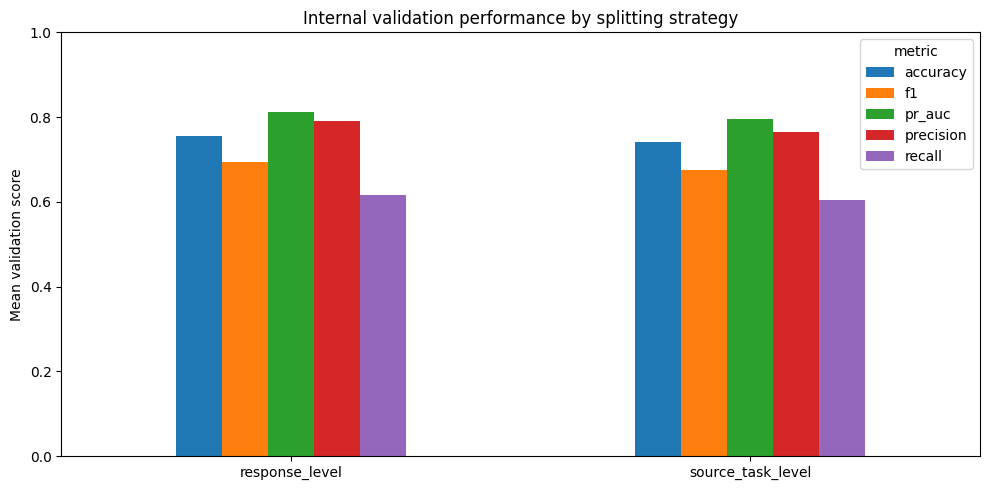

In [21]:
import matplotlib.pyplot as plt
plot_data = comparison.melt(id_vars='strategy', value_vars=metric_columns, var_name='metric', value_name='score')
ax = plot_data.groupby(['strategy', 'metric']).score.mean().unstack().plot(kind='bar', figsize=(10, 5))
ax.set_ylim(0, 1)
ax.set_ylabel('Mean validation score')
ax.set_xlabel('')
ax.set_title('Internal validation performance by splitting strategy')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'split_strategy_comparison.png', dpi=200)
plt.show()

## Pretrained encoder extension

This section directly addresses the recommendation to provide context to a
pretrained encoder. It requires a GPU runtime and downloads `distilroberta-base`.
The TF-IDF experiments above remain the primary baseline.

To keep the experiment feasible while preserving a meaningful split comparison,
the encoder uses context-plus-response input, three fixed seeds, two epochs,
and a 256-token maximum length. It evaluates both response-level and
source-task-level splits, checkpoints after every completed run, and performs
one final official-test training after validation-based selection.

In [22]:
!pip -q install -U transformers sentencepiece

In [23]:
import gc
import json
import random
import torch
from torch.utils.data import DataLoader, Dataset
from transformers import AutoModelForSequenceClassification, AutoTokenizer

ENCODER_NAME = 'distilroberta-base'
ENCODER_SEEDS = [13, 42, 2024]
ENCODER_EPOCHS = 2
ENCODER_BATCH_SIZE = 16
ENCODER_MAX_LENGTH = 256
ENCODER_LEARNING_RATE = 2e-5
ENCODER_INPUT_CONDITION = 'context_plus_response'
ENCODER_TEXT_COLUMN = 'context_plus_response'
ENCODER_DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

if ENCODER_DEVICE.type != 'cuda':
    raise RuntimeError(
        'A CUDA GPU is required for the encoder extension. '
        'Select a GPU Colab runtime and rerun this cell.'
    )

encoder_configuration = {
    'model_name': ENCODER_NAME,
    'input_condition': ENCODER_INPUT_CONDITION,
    'seeds': ENCODER_SEEDS,
    'epochs': ENCODER_EPOCHS,
    'batch_size': ENCODER_BATCH_SIZE,
    'max_length': ENCODER_MAX_LENGTH,
    'learning_rate': ENCODER_LEARNING_RATE,
    'device': str(ENCODER_DEVICE),
}
with (RESULTS_DIR / 'encoder_configuration.json').open('w', encoding='utf-8') as file:
    json.dump(encoder_configuration, file, indent=2)

print('Encoder:', ENCODER_NAME)
print('Input:', ENCODER_INPUT_CONDITION)
print('Device:', ENCODER_DEVICE)

Encoder: distilroberta-base
Input: context_plus_response
Device: cuda


In [24]:
class TextClassificationDataset(Dataset):
    def __init__(self, texts, labels, tokenizer):
        self.encodings = tokenizer(
            list(texts), truncation=True, max_length=ENCODER_MAX_LENGTH,
            padding=True,
        )
        self.labels = torch.tensor(list(labels), dtype=torch.long)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        item = {key: torch.tensor(value[index]) for key, value in self.encodings.items()}
        item['labels'] = self.labels[index]
        return item


def set_encoder_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def train_encoder(train, valid, seed, return_model=False):
    set_encoder_seed(seed)
    tokenizer = AutoTokenizer.from_pretrained(ENCODER_NAME)
    model = AutoModelForSequenceClassification.from_pretrained(
        ENCODER_NAME, num_labels=2
    ).to(ENCODER_DEVICE)
    train_dataset = TextClassificationDataset(
        train[ENCODER_TEXT_COLUMN], train.has_hallucination, tokenizer
    )
    valid_dataset = TextClassificationDataset(
        valid[ENCODER_TEXT_COLUMN], valid.has_hallucination, tokenizer
    )
    train_loader = DataLoader(
        train_dataset, batch_size=ENCODER_BATCH_SIZE, shuffle=True,
        generator=torch.Generator().manual_seed(seed),
    )
    valid_loader = DataLoader(valid_dataset, batch_size=ENCODER_BATCH_SIZE)
    class_counts = np.bincount(train.has_hallucination.astype(int), minlength=2)
    class_weights = len(train) / (2 * np.maximum(class_counts, 1))
    loss_function = torch.nn.CrossEntropyLoss(
        weight=torch.tensor(class_weights, dtype=torch.float32, device=ENCODER_DEVICE)
    )
    optimizer = torch.optim.AdamW(model.parameters(), lr=ENCODER_LEARNING_RATE)
    model.train()
    for epoch in range(ENCODER_EPOCHS):
        for batch_number, batch in enumerate(train_loader, start=1):
            batch = {key: value.to(ENCODER_DEVICE) for key, value in batch.items()}
            optimizer.zero_grad()
            logits = model(**{key: value for key, value in batch.items() if key != 'labels'}).logits
            loss = loss_function(logits, batch['labels'])
            loss.backward()
            optimizer.step()
            if batch_number % 100 == 0:
                print(
                    f'seed={seed}, epoch={epoch + 1}/{ENCODER_EPOCHS}, '
                    f'batch={batch_number}/{len(train_loader)}'
                )
        print(f'seed={seed}, epoch={epoch + 1}/{ENCODER_EPOCHS} complete')
    if return_model:
        return model, tokenizer
    model.eval()
    probabilities = []
    with torch.no_grad():
        for batch in valid_loader:
            batch.pop('labels')
            batch = {key: value.to(ENCODER_DEVICE) for key, value in batch.items()}
            logits = model(**batch).logits
            probabilities.extend(torch.softmax(logits, dim=1)[:, 1].cpu().numpy())
    del model, tokenizer, train_dataset, valid_dataset, train_loader, valid_loader
    gc.collect()
    torch.cuda.empty_cache()
    return np.asarray(probabilities)


def evaluate_encoder_split(train, valid, seed, strategy):
    probabilities = train_encoder(train, valid, seed)
    row = metrics(valid.has_hallucination, probabilities)
    row.update({
        'model': ENCODER_NAME,
        'input_condition': ENCODER_INPUT_CONDITION,
        'strategy': strategy,
        'seed': seed,
        'train_responses': len(train),
        'validation_responses': len(valid),
        'validation_positive_rate': valid.has_hallucination.mean(),
    })
    return row

In [25]:
encoder_rows = []
encoder_checkpoint = TABLES_DIR / 'encoder_validation_checkpoint.csv'
for seed in ENCODER_SEEDS:
    for strategy, splitter in [
        ('response_level', response_split),
        ('source_task_level', source_task_split),
    ]:
        train, valid = splitter(train_data, seed)
        row = evaluate_encoder_split(train, valid, seed, strategy)
        encoder_rows.append(row)
        pd.DataFrame(encoder_rows).to_csv(encoder_checkpoint, index=False)
        print(f'Saved encoder checkpoint after seed={seed}, strategy={strategy}')
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

encoder_validation_results = pd.DataFrame(encoder_rows)
encoder_validation_summary = encoder_validation_results.groupby(
    ['input_condition', 'strategy']
)[metric_columns].agg(['mean', 'std']).round(4)
display(encoder_validation_results)
display(encoder_validation_summary)
encoder_validation_results.to_csv(TABLES_DIR / 'encoder_validation_results_by_seed.csv', index=False)
encoder_validation_summary.to_csv(TABLES_DIR / 'encoder_validation_summary.csv')

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/480 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

... (18 outputs left out)

[transformers] RobertaForSequenceClassification LOAD REPORT from: distilroberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
classifier.out_proj.bias    | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.dense.bias       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


seed=2024, epoch=1/2, batch=100/747
seed=2024, epoch=1/2, batch=200/747
seed=2024, epoch=1/2, batch=300/747
seed=2024, epoch=1/2, batch=400/747
seed=2024, epoch=1/2, batch=500/747
seed=2024, epoch=1/2, batch=600/747
seed=2024, epoch=1/2, batch=700/747
seed=2024, epoch=1/2 complete
seed=2024, epoch=2/2, batch=100/747
seed=2024, epoch=2/2, batch=200/747
seed=2024, epoch=2/2, batch=300/747
seed=2024, epoch=2/2, batch=400/747
seed=2024, epoch=2/2, batch=500/747
seed=2024, epoch=2/2, batch=600/747
seed=2024, epoch=2/2, batch=700/747
seed=2024, epoch=2/2 complete
Saved encoder checkpoint after seed=2024, strategy=source_task_level


,f1,precision,recall,pr_auc,accuracy,model,input_condition,strategy,seed,train_responses,validation_responses,validation_positive_rate
0,0.602221,0.670944,0.546269,0.627767,0.676480,distilroberta-base,context_plus_response,response_level,13,11953,2989,0.448310
1,0.634570,0.694301,0.584302,0.642517,0.690611,distilroberta-base,context_plus_response,source_task_level,13,11949,2993,0.459739
2,0.607069,0.685446,0.544776,0.619752,0.683841,distilroberta-base,context_plus_response,response_level,42,11953,2989,0.448310
3,0.599245,0.691860,0.528497,0.630332,0.679745,distilroberta-base,context_plus_response,source_task_level,42,11960,2982,0.453052
4,0.621031,0.694009,0.561940,0.635006,0.692539,distilroberta-base,context_plus_response,response_level,2024,11953,2989,0.448310
5,0.589845,0.704641,0.507213,0.633079,0.690127,distilroberta-base,context_plus_response,source_task_level,2024,11944,2998,0.439293


f1         precision          \
                                           mean     std      mean     std   
input_condition       strategy                                              
context_plus_response response_level     0.6101  0.0098    0.6835  0.0117   
                      source_task_level  0.6079  0.0236    0.6969  0.0068   

                                        recall          pr_auc          \
                                          mean     std    mean     std   
input_condition       strategy                                           
context_plus_response response_level     0.551  0.0095  0.6275  0.0076   
                      source_task_level  0.540  0.0398  0.6353  0.0064   

                                        accuracy          
                                            mean     std  
input_condition       strategy                            
context_plus_response response_level      0.6843  0.0080  
                      source_task_level   0.6868  0.0061

In [26]:
encoder_input_selection = (
    encoder_validation_results.groupby('input_condition')['pr_auc']
    .mean()
    .sort_values(ascending=False)
    .rename('mean_encoder_internal_validation_pr_auc')
    .to_frame()
)
selected_encoder_input = encoder_input_selection.index[0]
if selected_encoder_input != ENCODER_INPUT_CONDITION:
    raise ValueError('Unexpected encoder input condition in validation results')
display(encoder_input_selection.round(4))
print('Selected encoder input condition:', selected_encoder_input)
encoder_input_selection.to_csv(TABLES_DIR / 'encoder_input_condition_selection.csv')

,mean_encoder_internal_validation_pr_auc
input_condition,
context_plus_response,0.6314


Selected encoder input condition: context_plus_response


In [27]:
if selected_encoder_input != ENCODER_INPUT_CONDITION:
    raise ValueError('The selected encoder input does not match the configured input')

final_encoder_model, final_encoder_tokenizer = train_encoder(
    train_data, test_data, ENCODER_SEEDS[0], return_model=True
)
final_test_dataset = TextClassificationDataset(
    test_data[ENCODER_TEXT_COLUMN], test_data.has_hallucination,
    final_encoder_tokenizer,
)
final_test_loader = DataLoader(final_test_dataset, batch_size=ENCODER_BATCH_SIZE)
final_encoder_model.eval()
final_probabilities = []
with torch.no_grad():
    for batch_number, batch in enumerate(final_test_loader, start=1):
        batch.pop('labels')
        batch = {key: value.to(ENCODER_DEVICE) for key, value in batch.items()}
        final_probabilities.extend(
            torch.softmax(final_encoder_model(**batch).logits, dim=1)[:, 1]
            .cpu().numpy()
        )
        if batch_number % 25 == 0:
            print(f'Official-test batches: {batch_number}/{len(final_test_loader)}')

encoder_official_test = pd.DataFrame([{
    'model': ENCODER_NAME,
    'split': 'official_test',
    'input_condition': selected_encoder_input,
    'seed': ENCODER_SEEDS[0],
    **metrics(test_data.has_hallucination, np.asarray(final_probabilities)),
}])
display(encoder_official_test.round(4))
encoder_official_test.to_csv(TABLES_DIR / 'encoder_selected_official_test_results.csv', index=False)

Loading weights:   0%|          | 0/101 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: distilroberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
classifier.out_proj.bias    | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.dense.bias       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


seed=13, epoch=1/2, batch=100/934
seed=13, epoch=1/2, batch=200/934
seed=13, epoch=1/2, batch=300/934
seed=13, epoch=1/2, batch=400/934
seed=13, epoch=1/2, batch=500/934
seed=13, epoch=1/2, batch=600/934
seed=13, epoch=1/2, batch=700/934
seed=13, epoch=1/2, batch=800/934
seed=13, epoch=1/2, batch=900/934
seed=13, epoch=1/2 complete
seed=13, epoch=2/2, batch=100/934
seed=13, epoch=2/2, batch=200/934
seed=13, epoch=2/2, batch=300/934
seed=13, epoch=2/2, batch=400/934
seed=13, epoch=2/2, batch=500/934
seed=13, epoch=2/2, batch=600/934
seed=13, epoch=2/2, batch=700/934
seed=13, epoch=2/2, batch=800/934
seed=13, epoch=2/2, batch=900/934
seed=13, epoch=2/2 complete
Official-test batches: 25/168
Official-test batches: 50/168
Official-test batches: 75/168
Official-test batches: 100/168
Official-test batches: 125/168
Official-test batches: 150/168


,model,split,input_condition,seed,f1,precision,recall,pr_auc,accuracy
0,distilroberta-base,official_test,context_plus_response,13,0.6264,0.6208,0.632,0.5827,0.7342
